# Ontdekken van Support Vector Machines

**OPMERKING: Voor dit voorbeeld zullen we het algoritme verkennen, dus we zullen het schalen overslaan en ook een train/test splitsing overslaan. In plaats daarvan zullen we bekijken hoe de verschillende parameters een SVM kunnen veranderen (het is het gemakkelijkst om de effecten te visualiseren met classificatie).**

## SVM - Classificatie

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Data

De gegevens die hier worden getoond, simuleren een medische studie waarbij met een virus geïnfecteerde muizen verschillende doseringen van twee medicijnen kregen toegediend, waarna na 2 weken werd gecontroleerd of ze nog steeds geïnfecteerd waren. Gegeven deze data is ons doel om een classificatiemodel te creëren dat kan voorspellen (gegeven twee doseringsmetingen) of de muis nog steeds geïnfecteerd zal zijn met het virus.

Je zal merken dat de groepen zeer scheidbaar zijn, wat met opzet gedaan om te verkennen hoe de verschillende parameters van een SVM-model zich gedragen.

In [2]:
df = pd.read_csv("../DATA/mouse_viral_study.csv")

In [3]:
df.head()

,Med_1_mL,Med_2_mL,Virus Present
0,6.508231,8.582531,0
1,4.126116,3.073459,1
2,6.427870,6.369758,0
3,3.672953,4.905215,1
4,1.580321,2.440562,1


In [4]:
df.columns

Index(['Med_1_mL', 'Med_2_mL', 'Virus Present'], dtype='object')

## Klasses

<Axes: xlabel='Med_1_mL', ylabel='Med_2_mL'>

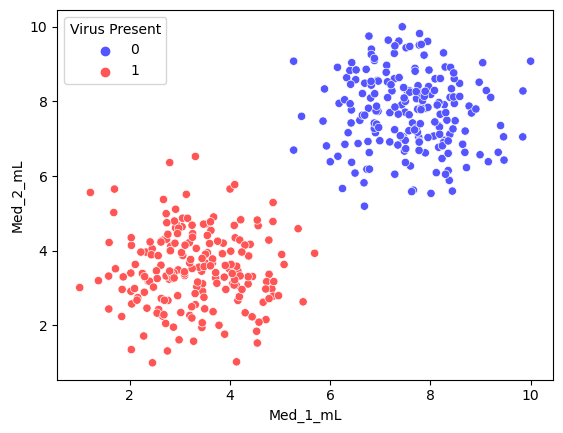

In [5]:
sns.scatterplot(x='Med_1_mL',y='Med_2_mL',hue='Virus Present',
                data=df,palette='seismic')

## Scheidend Hypervlak

Ons doel met SVM is om het beste scheidende hypervlak te creëren. In 2 dimensies is dit simpelweg een lijn.

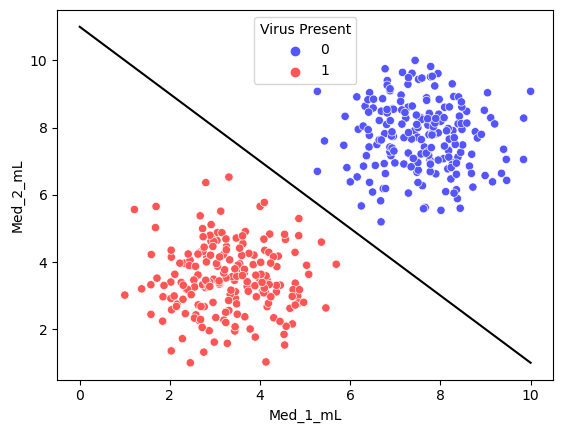

In [6]:
sns.scatterplot(x='Med_1_mL',y='Med_2_mL',hue='Virus Present',palette='seismic',data=df)

# We willen op de een of andere manier automatisch een scheidend hypervlak creëren (een lijn in 2D).
x = np.linspace(0,10,100)
m = -1
b = 11
y = m*x + b
plt.plot(x,y,'black')

## SVM - Support Vector Machine

In [7]:
from sklearn.svm import SVC # Support Vector Classifier

In [26]:
# help(SVC)

**OPMERKING: Voor dit voorbeeld zullen we het algoritme verkennen, dus we zullen voorlopig elke vorm van schalen of zelfs een train/test split overslaan.**

In [9]:
y = df['Virus Present']
X = df.drop('Virus Present',axis=1) 

In [50]:
model = SVC(kernel='linear', C=0.1)  # lagere C: grotere marge - test 0.01, 1, 1000
model.fit(X, y)

SVC(C=0.1, kernel='linear')

In [51]:
# https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html
# Op deze link kan je meer info zien inzake een manier op het hyperplane te plotten
# We kunnen deze code importeren als volgt:
from svm_margin_plot import plot_svm_boundary

In [52]:
X.columns

Index(['Med_1_mL', 'Med_2_mL'], dtype='object')

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


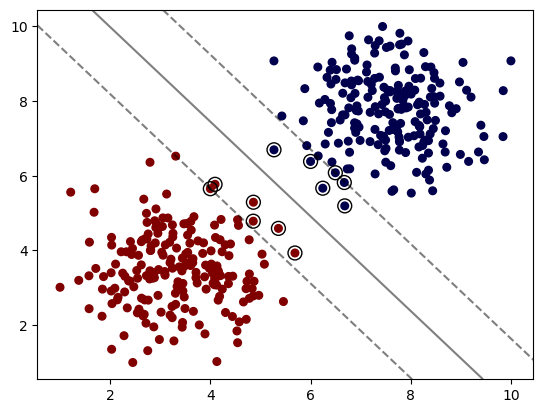

In [53]:
plot_svm_boundary(model,X,y)

## Hyperparameters

### C

C is een regularisatie parameter. Meer regularisatie betekent een eenvoudiger model, dus een hogere bias, en meer misclassificaties op de training data, dus een brederen marge.  De sterkte van de regularisatie is **omgekeerd** evenredig met C.  Indien er meerdere features zijn, is het geheel niet meer te visualiseren, en is het nagenoeg onmogelijk om zelf een goede waarde voor C te kiezen.  Dit gebeurt dan via grid search en cross validation.

In [54]:
model = SVC(kernel='linear', C=0.05)
model.fit(X, y)

SVC(C=0.05, kernel='linear')

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


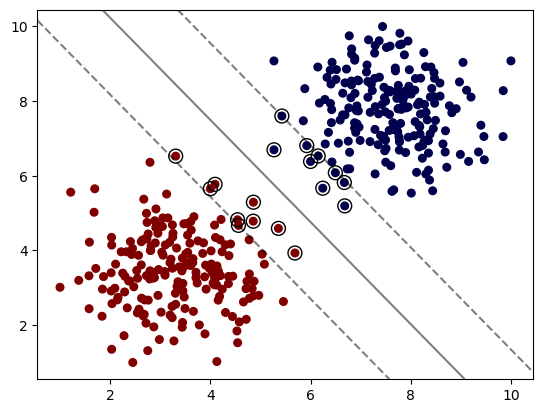

In [55]:
plot_svm_boundary(model,X,y)

### Gebruik van een Kernel

[Kiezen van een Kernel](https://stats.stackexchange.com/questions/18030/how-to-select-kernel-for-svm?rq=1)

Bij het trainen van een SVM met de Radial Basis Function (RBF) kernel moeten twee parameters in overweging worden genomen: C en gamma. De parameter C, die voor alle SVM kernels geldt, weegt de misclassificatie van trainingsvoorbeelden tegen de eenvoud van het beslissingsoppervlak af. Een lage C-waarde maakt het beslissingsoppervlak glad, terwijl een hoge C-waarde streeft naar correcte classificatie van alle trainingsvoorbeelden. Gamma bepaalt hoeveel invloed een enkel trainingsvoorbeeld heeft. Hoe groter gamma is, hoe dichter andere voorbeelden moeten zijn om beïnvloed te worden.

In de praktijk wordt vaak een reeks verschillende kernels getest en gevalideerd met cross-validation om te bepalen welke het beste presteert voor een gegeven probleem. Dit betekent dat de keuze van een kernel gebaseerd moet zijn op experimentele resultaten in plaats van alleen theoretische overwegingen.

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


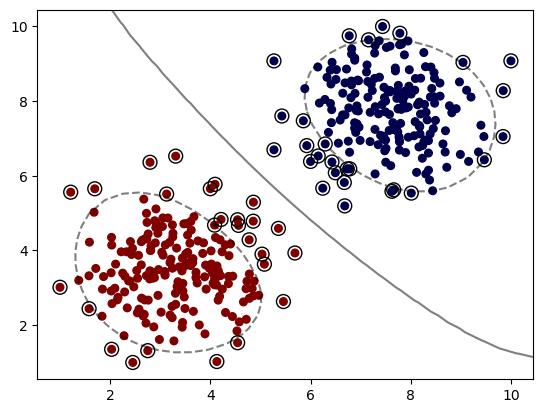

In [56]:
model = SVC(kernel='rbf', C=0.1) # radial basis function; de default voor SVM 
model.fit(X, y)
plot_svm_boundary(model,X,y)

De marge (stippellijn) omsluit onze clusters.  De punten "buiten de marge" zijn de support vectors; dit zijn in werkelijkheid de punten tussen het hypervlak wat de scheiding doet en de marge.  In werkelijkheid gebeurt dit namelijk in meer dimensies; hier projecteren we gewoon wat gebeurt in 2 dimensies waardoor het er cirkelvormig uitziet - wat het in werkelijkeid niet is!  Zelfs de marge (stippellijn) op ongeveer (1.8, 1.8) is in werkelijkheid gelegen tussen de punten en het scheidingsvlak.

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


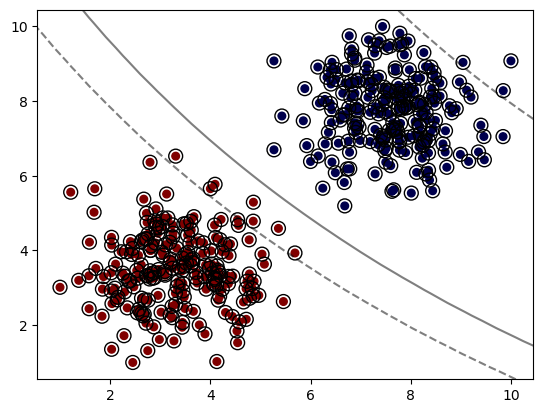

In [17]:
model = SVC(kernel='sigmoid')
model.fit(X, y)
plot_svm_boundary(model,X,y)

Bijna alle punten worden gebruikt als support vectors.  Deze kernel presteert hier dus niet goed; hij gebruikt zelfs punten die in het midden van de klasses liggen als support vectoren...

#### Graad (poly kernels allen)

Graad van de polynomial kernel functie ('poly').
Dit wordt genegeerd door alle andere kernels.

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


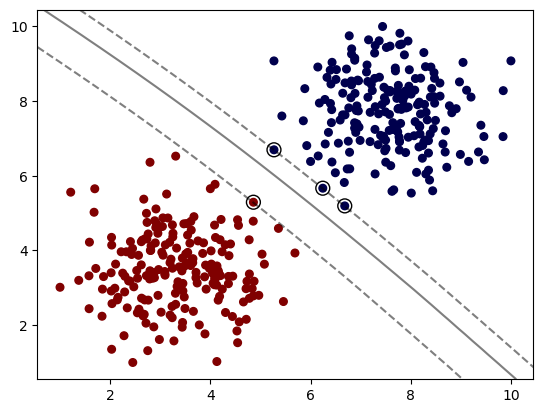

In [61]:
model = SVC(kernel='poly', C=1,degree=8)
model.fit(X, y)
plot_svm_boundary(model,X,y)

Hogere ordes geven weinig kromming.  Dit komt omdat een lineair model deze dataset reeds goed kan scheiden, waardoor hogere orde weinig bijkomende informatie biedt.

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


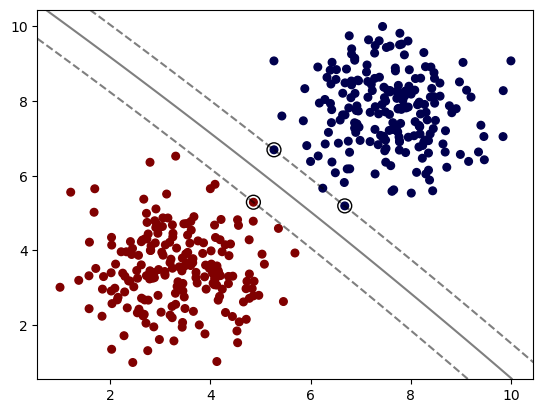

In [19]:
model = SVC(kernel='poly', C=1,degree=2)
model.fit(X, y)
plot_svm_boundary(model,X,y)

### gamma

gamma : {'scale', 'auto'} of float, default='scale'
    Kernel coefficient voor 'rbf', 'poly' en 'sigmoid'.

    - als ``gamma='scale'`` (default) wordt gekozen dan wordt 1 / (n_features * X.var()) als waarde voor gamma gebruikt,
    - bij 'auto' wordt 1 / n_features gebruikt.

/opt/conda/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


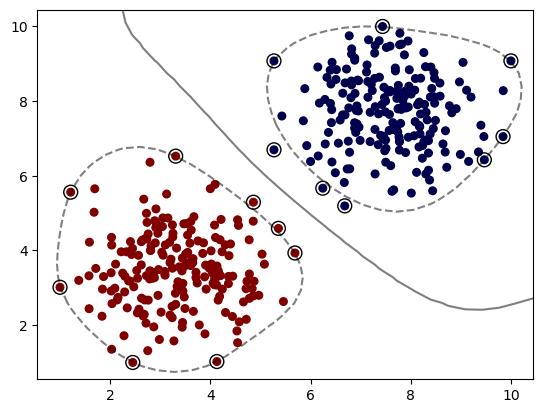

In [69]:
# zie help(SVC)
model = SVC(kernel='rbf', C=1,gamma=0.2)  # check 'auto' als waarde voor gamma (dit komt overeen met 1/2), ook 0.9, 2 -> overfitting!
# Bij zeer hoge gamma zoals 2 hebben de support vectors een meer 'regionaal' effect en krijgen we dus complexere grenzen.
model.fit(X, y)
plot_svm_boundary(model,X,y)

## Grid Search - bijna altijd nodig bij SVM!

Bedenk dat in dit eenvoudig voorbeeld de klassen eenvoudig kunnen worden gescheiden van elkaar.  Dit betekent dat elke variatie die wordt onderzocht een accuracy van 100% kan krijgen, waardoor het uitvoeren van een grid search in dit geval eigenlijk nutteloos is.

In [75]:
from sklearn.model_selection import GridSearchCV

In [80]:
svm = SVC()
param_grid = {'C':[0.01,0.1,1],'kernel':['linear','rbf']}
grid = GridSearchCV(svm,param_grid)

In [81]:
# Geen split Train|Test gedaan...
grid.fit(X,y)

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.01, 0.1, 1], 'kernel': ['linear', 'rbf']})

In [82]:
# 100% accuracy (as expected)
grid.best_score_

1.0

In [83]:
grid.best_params_

{'C': 0.01, 'kernel': 'linear'}

Dit was meer om het proces van grid search te herhalen. Herinner je dat in een echte situatie, zoals bij de oefening die komt, je een train-test split uitvoert en daarmee de finale evaluatie van je model uitvoert